# Process 이상 탐지 개선 결과 — v7

**IF·K-means·LOF 각각 단일 전체 모델**을 사용한다. Adapter별 모델은 없고, Adapter·Process별 정상 비교 통계는 유지한다.

목표: 5개 시나리오 각각 Recall ≥55%, Accuracy·Precision·F1은 v6 이상, 오탐률(FPR)은 각 시나리오 및 전체 **6% 이하**. 사용자가 마지막으로 오탐률 조건만 완화했으며, 이전의 ‘v6 오탐률 이하’ 조건과 구분한다.

이 결과는 반복 사용한 합성 벤치마크의 **개발·선택 결과**다. 외부 블라인드 테스트나 운영 성능 보장이 아니다.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]if(p/'reports/shared_model_v7/release/summary.json').exists())
LOG=ROOT/'reports/shared_model_v7/release';BASE=ROOT/'reports/shared_model_v6/release'
read=lambda p:json.loads(p.read_text(encoding='utf-8'))
s=read(LOG/'summary.json');old=read(BASE/'summary.json');sel=read(LOG/'selection.json');handoff=read(LOG/'handoff/manifest.json')
alg=['if','kmeans','lof'];names={'if':'Isolation Forest','kmeans':'MiniBatch K-means','lof':'LOF'}
tasks=['individual_delay','group_delay','time_burst','input_stop','gradual_degradation']
labels=['개별 지연','집단 지연','시간대 폭주','입력 중단','점진적 악화']
keys=['accuracy','precision','recall','f1','normal_false_positive_rate']
knames=dict(zip(keys,['Accuracy','Precision','Recall','F1','오탐률(FPR)']))
colors=['#2563eb','#d97706','#059669']
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False,'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
def rows(summary):
    return pd.DataFrame([{'시나리오':labels[tasks.index(d['dataset'])],'모델':names[r['method']],**{knames[k]:100*r[k]for k in keys},**{k:r[k]for k in ['tp','fp','fn','tn']}}for d in summary['datasets']for r in d['metrics']])
def metric(summary,t,a,k):return next(r[k]for d in summary['datasets']if d['dataset']==t for r in d['metrics']if r['method']==a)

## 1. 무엇을 평가했나

시나리오마다 이상 5,000개 사례와 짝을 이루는 정상 사례를 평가했다. 표의 한 판정은 **Process 로그 한 행이 아니라, 특정 Adapter·Process의 한 분 감시 결과**다. 하나의 사례에는 여러 분이 포함되므로 사례 수와 판정 수가 다르다.

| 지표 | 읽는 방법 |
|---|---|
| Recall | 실제 이상 분 중 탐지한 비율. 높을수록 적게 놓침 |
| Precision | 경보를 낸 분 중 실제 이상인 비율. 높을수록 경보 신뢰도가 높음 |
| F1 | Precision과 Recall을 함께 보는 지표 |
| Accuracy | 정상·이상 전체에서 맞힌 비율. 정상 비중에 영향을 받음 |
| FPR | 정상 분 중 잘못 경보한 비율. 낮을수록 좋음 |

모든 STATUS는 S이며 기존 하드 룰을 통과한 평가셋이다. S라고 실제 정상임을 보장하는 것은 아니다. 평가 시나리오 정답은 지표 계산·개발 설정 선택에만 사용하며 추론 입력에는 넣지 않는다.

In [2]:
display(pd.DataFrame([{'전체 판정':s['protocol']['decisions'],'정상 판정':s['protocol']['normal'],'이상 판정':s['protocol']['anomaly'],'사례/시나리오':'이상 5,000 + 짝 정상 5,000'}]))
pooled=pd.DataFrame([{'모델':names[r['method']],**{knames[k]:100*r[k]for k in keys}}for r in s['pooled']])
display(pooled.round(3))
display(rows(s).round(3))

,전체 판정,정상 판정,이상 판정,사례/시나리오
0,1927972,1596121,331851,"이상 5,000 + 짝 정상 5,000"


,모델,Accuracy,Precision,Recall,F1,오탐률(FPR)
0,Isolation Forest,94.007,90.326,73.001,80.745,1.626
1,MiniBatch K-means,93.663,92.932,68.383,78.790,1.081
2,LOF,93.809,89.597,72.441,80.111,1.749


,시나리오,모델,Accuracy,Precision,Recall,F1,오탐률(FPR),tp,fp,fn,tn
0,개별 지연,Isolation Forest,98.111,99.799,77.911,87.507,0.015,3968,8,1125,54883
1,개별 지연,MiniBatch K-means,97.166,99.912,66.680,79.981,0.005,3396,3,1697,54888
2,개별 지연,LOF,97.543,99.807,71.196,83.108,0.013,3626,7,1467,54884
3,집단 지연,Isolation Forest,96.784,86.952,92.675,89.722,2.483,51079,7665,4037,301049
4,집단 지연,MiniBatch K-means,97.787,90.584,95.299,92.882,1.769,52525,5460,2591,303254
5,집단 지연,LOF,96.686,85.706,93.760,89.552,2.792,51677,8619,3439,300095
6,시간대 폭주,Isolation Forest,94.116,81.522,56.475,66.725,1.493,23529,5333,18134,351860
7,시간대 폭주,MiniBatch K-means,94.430,85.991,55.764,67.655,1.060,23233,3785,18430,353408
8,시간대 폭주,LOF,94.282,84.502,55.423,66.941,1.186,23091,4235,18572,352958
9,입력 중단,Isolation Forest,95.650,95.333,76.414,84.832,0.708,61123,2992,18866,419507


## 2. v6에서 얼마나 달라졌나

옅은 막대는 v6, 진한 막대는 v7이다. 위는 **놓치는 이상을 얼마나 줄였는지**, 아래는 **경보 신뢰도와 탐지율의 균형**을 보여준다. 점선은 Recall의 최소 목표다. F1이 올라도 다른 시나리오의 Precision이나 Accuracy가 떨어지면 채택하지 않는다.

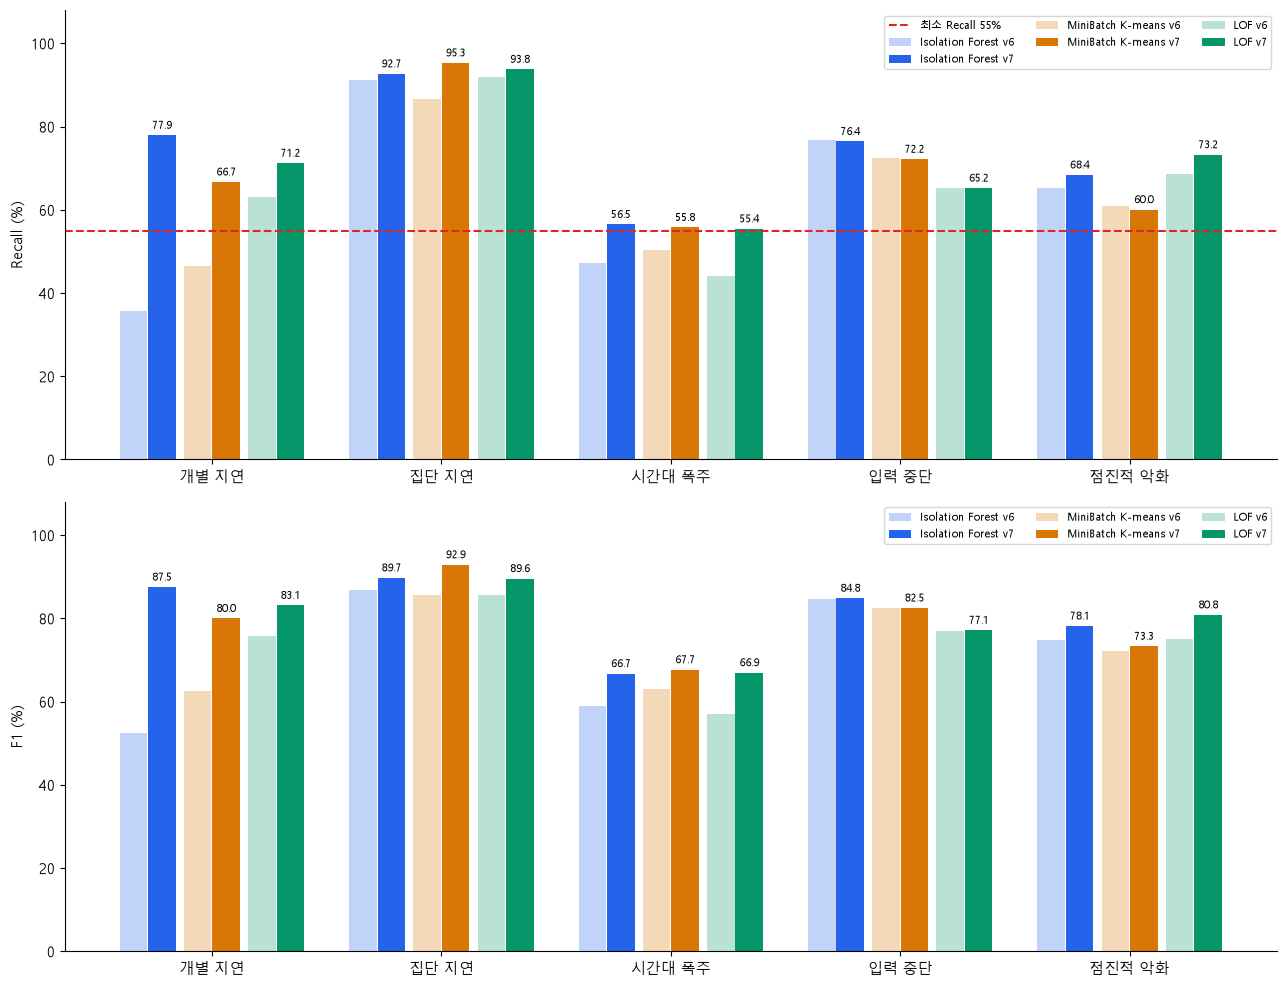

Accuracy 변화(%p)  Precision 변화(%p)  Recall 변화(%p)  \
시나리오   모델                                                                    
개별 지연  Isolation Forest            3.6043            1.1516        42.1166   
       MiniBatch K-means           1.8722            3.8110        20.2238   
       LOF                         0.9886            5.2287         8.1681   
집단 지연  Isolation Forest            0.9493            3.9837         1.4460   
       MiniBatch K-means           2.2346            6.1591         8.6762   
       LOF                         1.3550            5.5667         1.7890   
시간대 폭주 Isolation Forest            0.9502            2.5248         9.3752   
       MiniBatch K-means           0.6138            1.8323         5.4989   
       LOF                         1.2345            3.8795        11.4034   
입력 중단  Isolation Forest            0.0625            0.7401        -0.2488   
       MiniBatch K-means           0.0565            0.6821        -0.1888   
       LOF                         0.0663            0.7278        -0.1288   
점진적 악화 Isolation Forest            1.4037            3.4537         3.1262   
       MiniBatch K-means           0.8472            5.7350        -0.8614   
       LOF                         2.7328            7.3955         4.7070   

                          F1 변화(%p)  오탐률(FPR) 변화(%p)  
시나리오   모델                                             
개별 지연  Isolation Forest     34.9784          -0.0310  
       MiniBatch K-means    17.3471          -0.1694  
       LOF                   7.4628          -0.3225  
집단 지연  Isolation Forest      2.8196          -0.8607  
       MiniBatch K-means     7.3720          -1.0845  
       LOF                   3.9038          -1.2776  
시간대 폭주 Isolation Forest      7.7114           0.0325  
       MiniBatch K-means     4.7158          -0.0440  
       LOF                   9.9943          -0.0484  
입력 중단  Isolation Forest      0.1423          -0.1214  
       MiniBatch K-means     0.1290          -0.1030  
       LOF                   0.1545          -0.1032  
점진적 악화 Isolation Forest      3.3115          -0.8332  
       MiniBatch K-means     1.2038          -1.4131  
       LOF                   5.8444          -2.0790

In [3]:
fig,axes=plt.subplots(2,1,figsize=(13,10));x=np.arange(5)
for ax,k in zip(axes,['recall','f1']):
    for i,(a,color)in enumerate(zip(alg,colors)):
        previous=[100*metric(old,t,a,k)for t in tasks];current=[100*metric(s,t,a,k)for t in tasks];pos=x+(i-1)*.28
        ax.bar(pos-.062,previous,width=.12,color=color,alpha=.28,label=names[a]+' v6')
        bars=ax.bar(pos+.062,current,width=.12,color=color,label=names[a]+' v7');ax.bar_label(bars,fmt='%.1f',padding=3,fontsize=8)
    if k=='recall':ax.axhline(55,color='#dc2626',ls='--',label='최소 Recall 55%')
    ax.set(xticks=x,xticklabels=labels,ylim=(0,108),ylabel=knames[k]+' (%)');ax.legend(ncol=3,fontsize=8,loc='upper right')
fig.tight_layout();fig.savefig(LOG/'recall_f1_comparison.png',dpi=150,bbox_inches='tight');display(fig);plt.close(fig)
changes=rows(s).set_index(['시나리오','모델'])[list(knames.values())]-rows(old).set_index(['시나리오','모델'])[list(knames.values())]
display(changes.rename(columns=lambda c:c+' 변화(%p)').round(4))

### 오탐률은 별도로 확인

6%는 허용 상한이지 목표값이 아니다. 작은 수치 차이가 보이도록 표에는 소수 넷째 자리까지 표시한다. FPR 증가는 양수일 때 나쁜 방향이다. 이 상한은 이번 벤치마크에서 확인한 값이며 운영에서 보장되는 한계가 아니다.

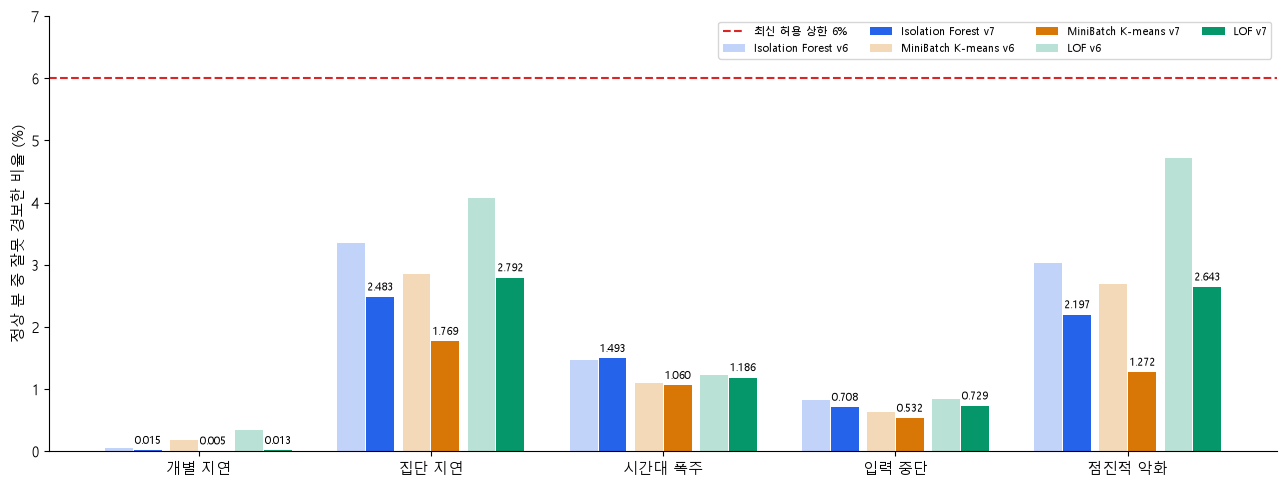

,모델,시나리오,v6 FPR (%),v7 FPR (%)
0,Isolation Forest,개별 지연,0.0455,0.0146
1,MiniBatch K-means,개별 지연,0.1749,0.0055
2,LOF,개별 지연,0.3352,0.0128
3,Isolation Forest,집단 지연,3.3435,2.4829
4,MiniBatch K-means,집단 지연,2.8531,1.7686
5,LOF,집단 지연,4.0695,2.7919
6,Isolation Forest,시간대 폭주,1.4606,1.4930
7,MiniBatch K-means,시간대 폭주,1.1036,1.0597
8,LOF,시간대 폭주,1.2341,1.1856
9,Isolation Forest,입력 중단,0.8296,0.7082


In [4]:
fig,ax=plt.subplots(figsize=(13,5));x=np.arange(5)
for i,(a,color)in enumerate(zip(alg,colors)):
    pos=x+(i-1)*.28
    ax.bar(pos-.062,[100*metric(old,t,a,'normal_false_positive_rate')for t in tasks],width=.12,color=color,alpha=.28,label=names[a]+' v6')
    bars=ax.bar(pos+.062,[100*metric(s,t,a,'normal_false_positive_rate')for t in tasks],width=.12,color=color,label=names[a]+' v7');ax.bar_label(bars,fmt='%.3f',padding=3,fontsize=8)
ax.axhline(6,color='#dc2626',ls='--',label='최신 허용 상한 6%');ax.set(xticks=x,xticklabels=labels,ylabel='정상 분 중 잘못 경보한 비율 (%)',ylim=(0,7));ax.legend(ncol=4,fontsize=8)
fig.tight_layout();fig.savefig(LOG/'false_positive_comparison.png',dpi=150,bbox_inches='tight');display(fig);plt.close(fig)
display(pd.DataFrame([{'모델':names[a],'시나리오':labels[j],'v6 FPR (%)':100*metric(old,t,a,'normal_false_positive_rate'),'v7 FPR (%)':100*metric(s,t,a,'normal_false_positive_rate')}for j,t in enumerate(tasks)for a in alg]).round(4))

## 3. 모델별로 무엇이 다른가

공통적으로 소요시간·처리 건수·최근 요청 수·지연의 지속 및 증가·입력 공백을 숫자로 만든다. **정상 통계와 시계열 신호를 결합한 파이프라인**이므로, 성능 향상을 전부 순수 IF/K-means/LOF 알고리즘의 효과로 해석하면 안 된다.

| 모델 | 이번 구현의 학습 코어와 차이 | 기대한 역할 |
|---|---|---|
| IF | 여러 관측 신호 중 가장 큰 정상 이탈을 요약한 1차원 코어. 현재 실행의 조건부 소요시간·정상 이웃 거리 통계로 판정을 보강 | 개별 지연 |
| K-means | 다섯 신호 집단의 최대·평균과 결합 크기, 12개 입력. 정상 공분산 보정 후 8개 군집까지의 상대 거리 | 집단 지연 |
| LOF | 11개 요약 입력에서 가까운 정상 이웃의 밀도와 비교. 최근 지연·추세를 포함 | 점진적 악화 |

K-means는 최근 여러 지연 신호의 조합을 보존하도록 군집 입력을 변경했다. 단순히 경보선을 낮춘 변경이 아니다. 반면 IF·LOF는 기존 학습 코어를 유지하고 정상 비교 통계 및 경보 기준을 개선했다. **현재 결과는 이 피처·설정·벤치마크에서의 강점이지 알고리즘의 보편적 우열이 아니다.**

In [5]:
role=pd.DataFrame(s['requested_roles']['requested_roles'])
for k in ['F1','Precision','Recall']:role[k]*=100
role['모델']=role.requested_model.map(names);role['시나리오']=role.task.map(dict(zip(tasks,labels)))
display(role[['모델','시나리오','Precision','Recall','F1','F1_gap_to_best_other_pp','observed_best_F1']].round(3))
params=[]
for a in alg:
    r=sel['models'][a];v=r['record'];p=v['actual_estimator_parameters']
    params.append({'모델':names[a],'학습 추정기':r['actual_unique_fault_estimators'],'추정기 입력 수':r['actual_estimator_features'],'실제 fit 행':v['fit_rows'],'주요 설정':str({k:p[k]for k in ['n_estimators','max_samples','max_features','n_clusters','batch_size','n_init','max_iter','n_neighbors','novelty','random_state']if k in p}),'시계열 상태 설정':str(v['filter_parameters'])})
display(pd.DataFrame(params))

,모델,시나리오,Precision,Recall,F1,F1_gap_to_best_other_pp,observed_best_F1
0,Isolation Forest,개별 지연,99.799,77.911,87.507,4.399,True
1,MiniBatch K-means,집단 지연,90.584,95.299,92.882,3.159,True
2,LOF,점진적 악화,90.174,73.234,80.826,2.686,True


,모델,학습 추정기,추정기 입력 수,실제 fit 행,주요 설정,시계열 상태 설정
0,Isolation Forest,1,1,19793,"{'n_estimators': 400, 'max_samples': 64, 'max_...",{'explicit_intermittent_PMF_state_feature': Tr...
1,MiniBatch K-means,1,12,19793,"{'n_clusters': 8, 'batch_size': 2048, 'n_init'...",{'explicit_intermittent_PMF_state_feature': Tr...
2,LOF,1,11,4096,"{'n_neighbors': 800, 'novelty': True}",{'explicit_intermittent_PMF_state_feature': Tr...


## 4. 어떤 피처를 사용하나

‘업무’라는 표현 대신 **Adapter Type + Process ID**로 비교 집단을 명시한다. ‘처리량’은 totalCount 등 처리 건수이고, ‘요청 수’는 해당 감시 분에 유입된 실행 개수다. 둘은 다르다.

| 관측 정보 | 의미 |
|---|---|
| 현재 실행의 정상 대비 지연 | 같은 Adapter·Process·처리 건수 조건의 평소 소요시간보다 얼마나 느린지 |
| 정상 이웃과의 거리 | 조건이 비슷한 정상 실행과 소요시간·처리 건수 조합이 얼마나 다른지 |
| 최근 지연의 지속 | 과거 완료 관측들의 지연이 계속 누적되는지 |
| 최근 지연의 추세 | 과거 완료 관측들을 따라 소요시간 잔차가 증가하는지 |
| 요청 수 증가 | 현재까지 도착한 분 단위 실행 수가 정상 시간대 분포보다 큰지 |
| 입력 공백 | 평소 기대되는 요청이 최근 들어오지 않는 정도 |

참고가 부족하면 더 넓은 정상 집단으로 대체한다. Process ID 문자열 자체를 숫자 벡터에 넣는 것이 아니라 **정상 비교 통계를 고르는 키**로 쓴다. 추론 시 정답 시나리오나 장애 종료 시점을 보지 않는다.

In [6]:
for a in alg:
    display(Markdown('### '+names[a]+' — 학습 코어 입력'))
    display(pd.Series(sel['models'][a]['record'].get('transformed_columns',[]),name='변환 피처').to_frame())

### Isolation Forest — 학습 코어 입력

,변환 피처
0,evidence_joint_max


### MiniBatch K-means — 학습 코어 입력

,변환 피처
0,evidence_point_peak
1,evidence_point_mean
2,evidence_delay_peak
3,evidence_delay_mean
4,evidence_trend_peak
5,evidence_trend_mean
6,evidence_burst_peak
7,evidence_burst_mean
8,evidence_gap_peak
9,evidence_gap_mean


### LOF — 학습 코어 입력

,변환 피처
0,evidence_point_peak
1,evidence_point_mean
2,evidence_delay_peak
3,evidence_delay_mean
4,evidence_trend_peak
5,evidence_trend_mean
6,evidence_burst_peak
7,evidence_burst_mean
8,evidence_gap_peak
9,evidence_gap_mean


### 입력 피처의 실제 분포 예시

각 시나리오의 observed·normal 코호트에서 첫 번째 동결 캐시 청크를 각각 읽어 **이상 사례 500개와 짝 정상 사례 500개**를 함께 비교한다. 이상 사례 내부의 정상 분만 정상 표본으로 대신 사용하지 않는다. **분포를 읽기 위한 일부 사례 그림**이며, 위 성능표는 전수 평가 결과다. 파랑·주황의 각 집단 합은 100%다. 표시 범위 밖 값은 양 끝 막대에 모은다. 피처 하나만으로 장애를 확정하는 규칙은 아니다.

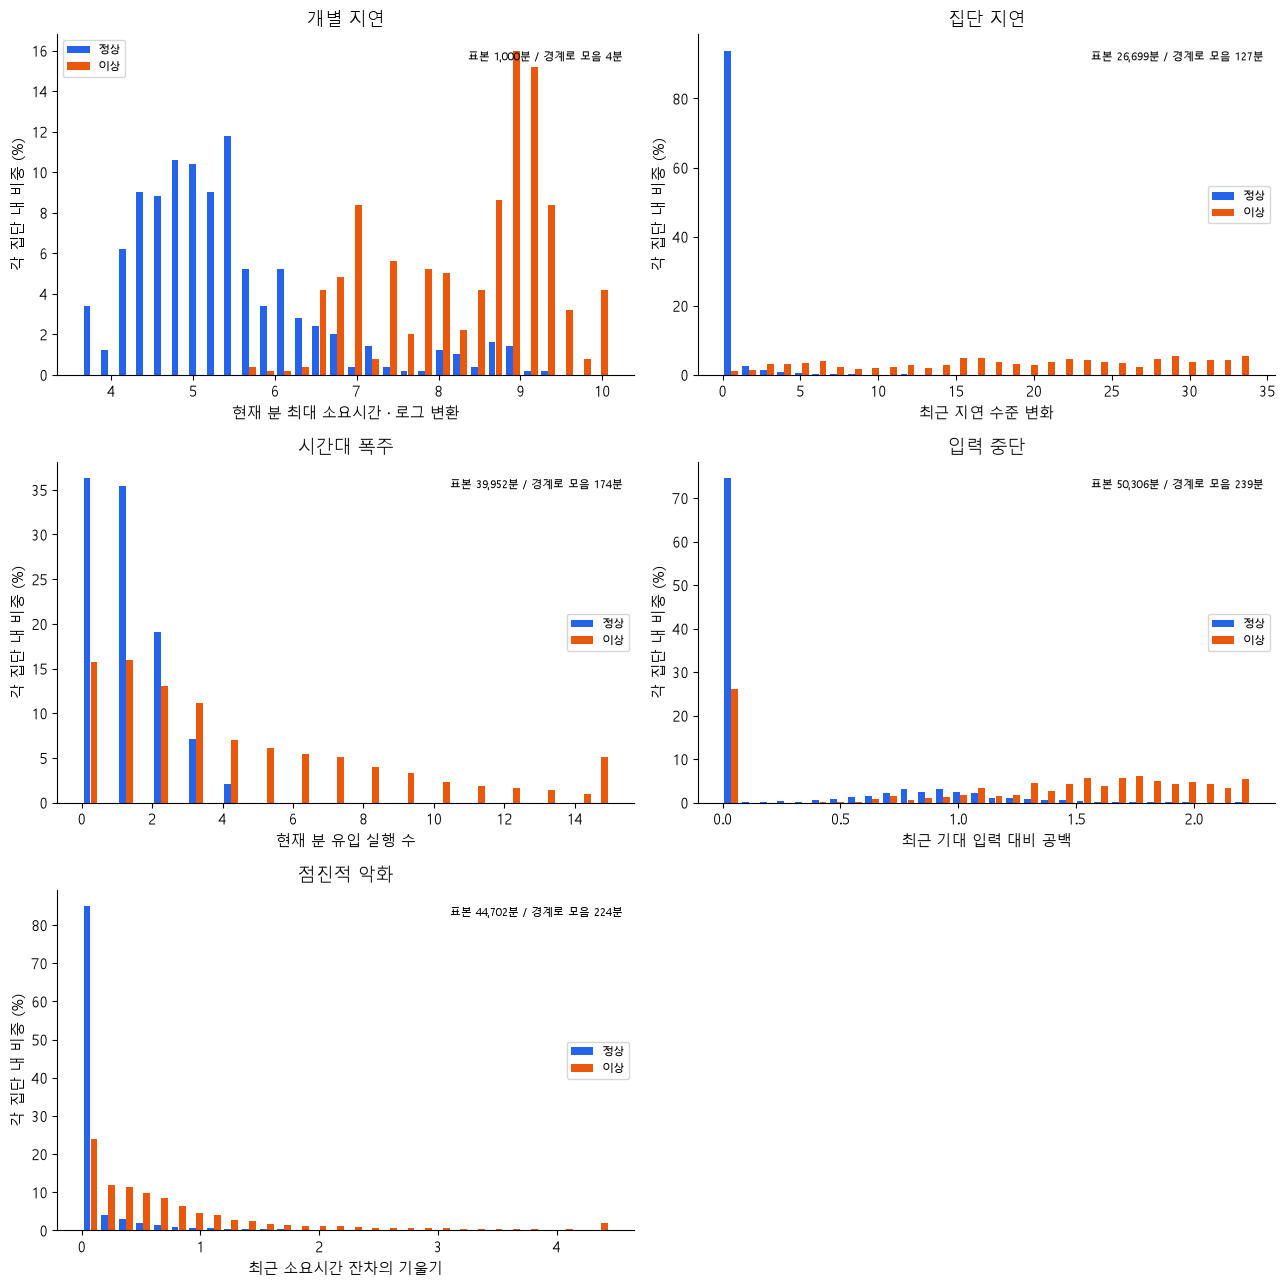

In [7]:
import joblib
features=['log_max_duration_1m','seq_last_shift','native_execution_arrivals','gap_expected_recent','seq_delay_slope']
f_labels=['현재 분 최대 소요시간 · 로그 변환','최근 지연 수준 변화','현재 분 유입 실행 수','최근 기대 입력 대비 공백','최근 소요시간 잔차의 기울기']
fig,axes=plt.subplots(3,2,figsize=(13,13));axes=axes.ravel()
for j,(t,key,label)in enumerate(zip(tasks,features,f_labels)):
    index=read(ROOT/'reports/shared_model_v2/feature_cache/4f5469a098b82372'/t/'index.json')
    chosen=[next(e for e in index if e['cohort']==c)for c in ['observed','normal']]
    packs=[joblib.load(ROOT/'reports/shared_model_v3/feature_cache/4f5469a098b82372'/t/e['file'])for e in chosen]
    f=pd.concat([p['frame']for p in packs],ignore_index=True);y=np.concatenate([np.asarray(p['metadata']['truth'],bool)for p in packs]);value=f[key].to_numpy(float)
    available=np.isfinite(value)
    if j in [0,1,4]:available&=f.latency_assessed.to_numpy(bool)
    v=value[available];truth=y[available];lo=float(np.quantile(v,.005));hi=max(lo+.1,float(np.quantile(v,.995)));edges=np.linspace(lo,hi,31);width=np.diff(edges);centers=(edges[:-1]+edges[1:])/2;ax=axes[j]
    for shift,mask,color,name in [(-.2,~truth,'#2563eb','정상'),(.2,truth,'#ea580c','이상')]:
        hist=np.histogram(np.clip(v[mask],lo,hi),bins=edges)[0]/max(mask.sum(),1)*100;ax.bar(centers+shift*width,hist,width=.39*width,color=color,label=name)
    ax.set(title=labels[j],xlabel=label,ylabel='각 집단 내 비중 (%)');ax.legend(fontsize=8)
    ax.text(.98,.95,f'표본 {len(v):,}분 / 경계로 모음 {int(((v<lo)|(v>hi)).sum()):,}분',transform=ax.transAxes,ha='right',va='top',fontsize=8)
axes[-1].axis('off');fig.tight_layout();fig.savefig(LOG/'input_feature_distribution.png',dpi=130,bbox_inches='tight');display(fig);plt.close(fig)

## 5. 분포와 경보선은 어떻게 읽나

아래는 **모델에 실제로 입력되어 계산된 최종 경보 점수의 분포**다. 파랑은 정상, 주황은 이상이다. 빨간 점선 **1을 초과하면 경보**다. 정상 막대는 왼쪽, 이상 막대는 오른쪽에 많을수록 좋다. 점수는 이상 확률이 아니다. 정상 집단별 기준을 적용한 뒤 같은 경보선 1로 맞춘 값이다.

각 정상·이상 집단의 막대 합은 각각 100%다. 그림 범위 밖 값은 양 끝 막대에 모으고 그 개수를 표시한다. 지표 계산에는 그림의 절단이 아닌 원래 점수를 사용한다.

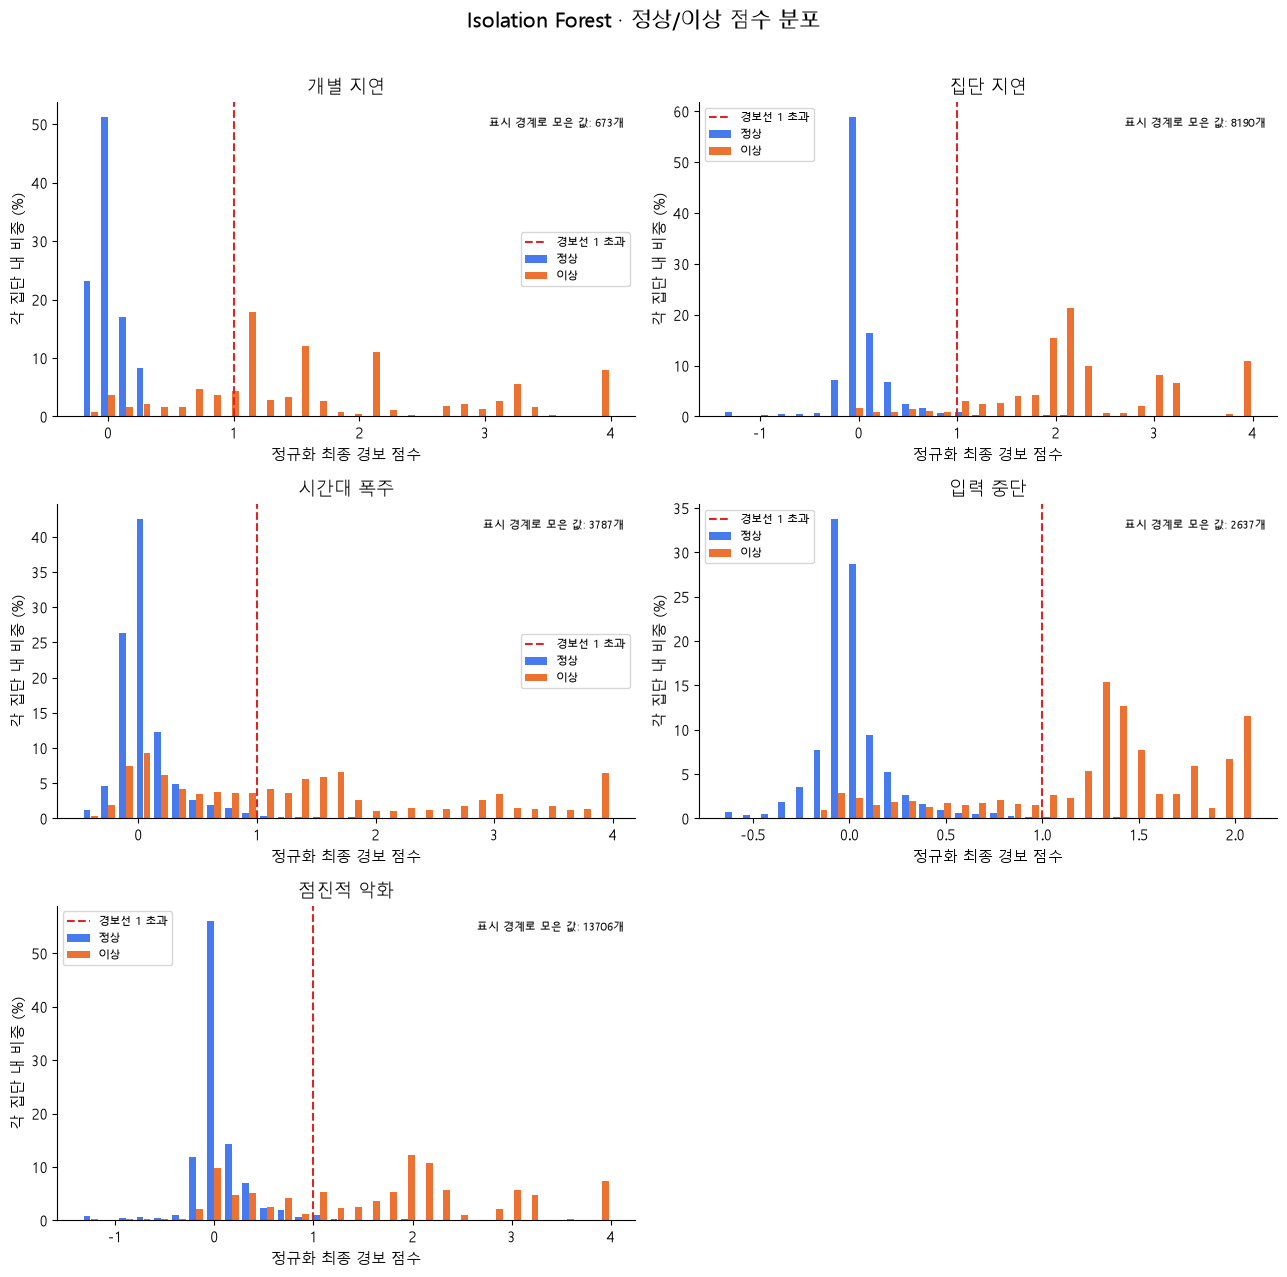

In [8]:
a='if';ai=0
fig,axes=plt.subplots(3,2,figsize=(13,13));axes=axes.ravel()
for j,t in enumerate(tasks):
    z=np.load(LOG/(t+'_scores.npz'));score=z['scores'][:,ai];y=z['y'];ax=axes[j]
    lo=min(0.,float(np.quantile(score,.005)));hi=max(1.5,min(4.,float(np.quantile(score,.995))));edges=np.linspace(lo,hi,31);width=np.diff(edges);centers=(edges[:-1]+edges[1:])/2
    for shift,mask,color,label in [(-.2,~y,'#2563eb','정상'),(.2,y,'#ea580c','이상')]:
        hist=np.histogram(np.clip(score[mask],lo,hi),bins=edges)[0]/max(mask.sum(),1)*100
        ax.bar(centers+shift*width,hist,width=.39*width,color=color,alpha=.85,label=label)
    ax.axvline(1.,color='#dc2626',ls='--',label='경보선 1 초과')
    ax.set(title=labels[j],xlabel='정규화 최종 경보 점수',ylabel='각 집단 내 비중 (%)')
    ax.text(.98,.95,'표시 경계로 모은 값: '+str(int(((score<lo)|(score>hi)).sum()))+'개',ha='right',va='top',transform=ax.transAxes,fontsize=8)
    ax.legend(fontsize=8)
axes[-1].axis('off');fig.suptitle(names[a]+' · 정상/이상 점수 분포',fontsize=15);fig.tight_layout(rect=[0,0,1,.97]);fig.savefig(LOG/(a+'_score_distribution.png'),dpi=130,bbox_inches='tight');display(fig);plt.close(fig)

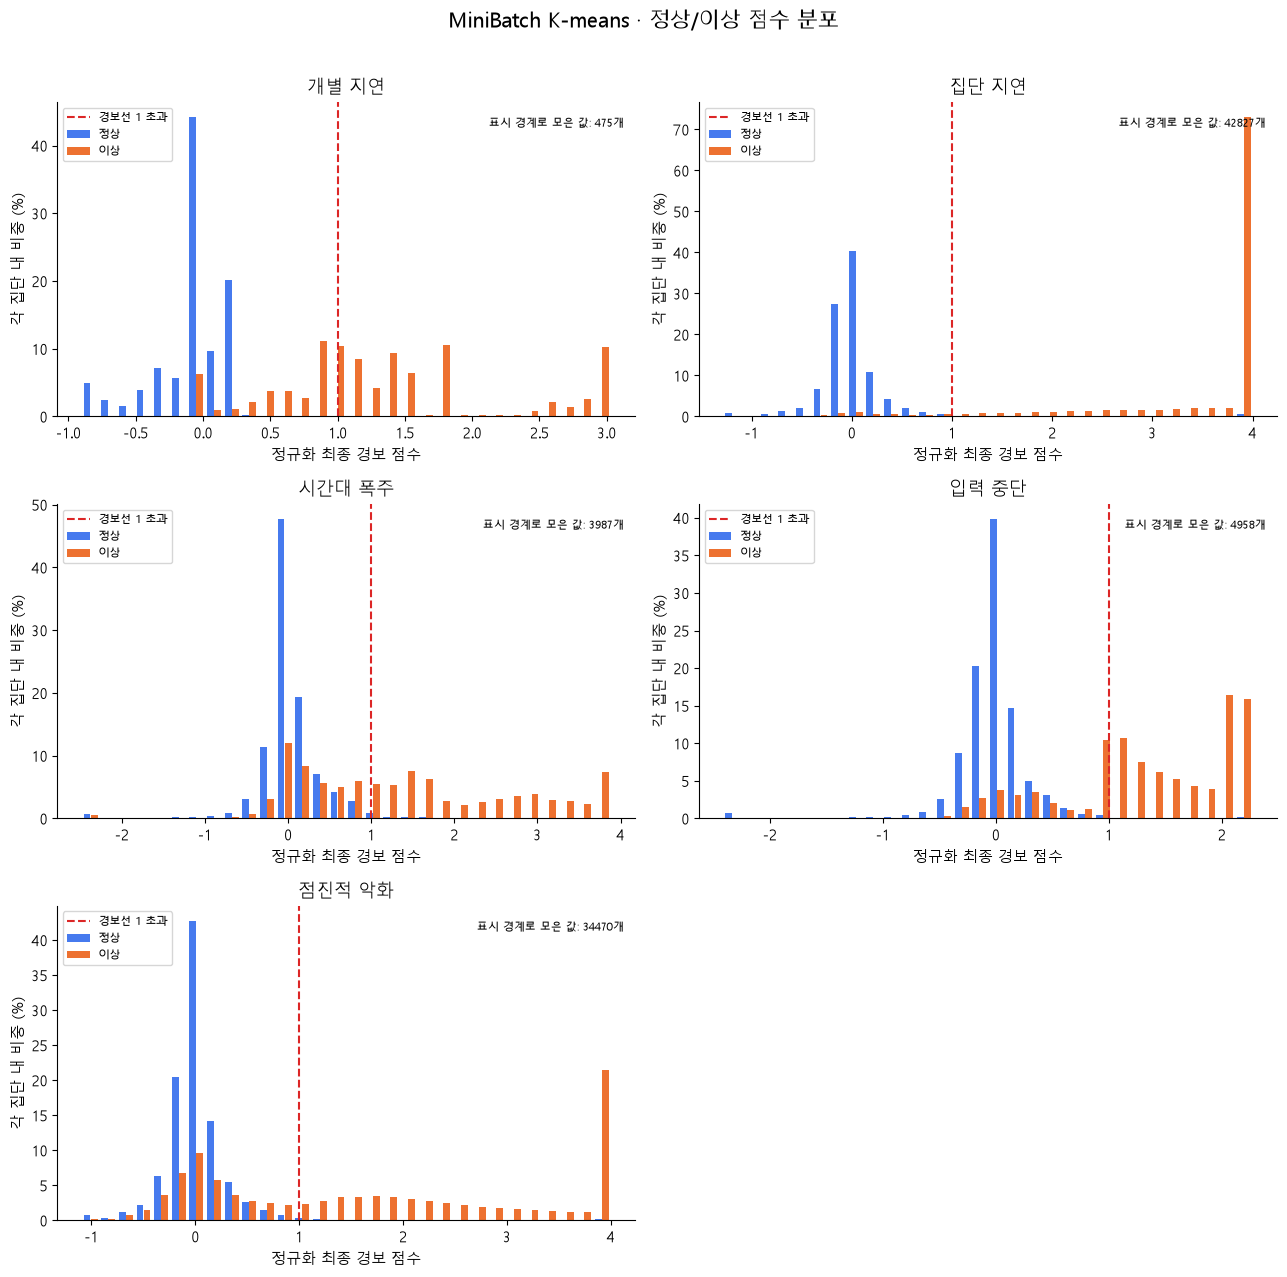

In [9]:
a='kmeans';ai=1
fig,axes=plt.subplots(3,2,figsize=(13,13));axes=axes.ravel()
for j,t in enumerate(tasks):
    z=np.load(LOG/(t+'_scores.npz'));score=z['scores'][:,ai];y=z['y'];ax=axes[j]
    lo=min(0.,float(np.quantile(score,.005)));hi=max(1.5,min(4.,float(np.quantile(score,.995))));edges=np.linspace(lo,hi,31);width=np.diff(edges);centers=(edges[:-1]+edges[1:])/2
    for shift,mask,color,label in [(-.2,~y,'#2563eb','정상'),(.2,y,'#ea580c','이상')]:
        hist=np.histogram(np.clip(score[mask],lo,hi),bins=edges)[0]/max(mask.sum(),1)*100
        ax.bar(centers+shift*width,hist,width=.39*width,color=color,alpha=.85,label=label)
    ax.axvline(1.,color='#dc2626',ls='--',label='경보선 1 초과')
    ax.set(title=labels[j],xlabel='정규화 최종 경보 점수',ylabel='각 집단 내 비중 (%)')
    ax.text(.98,.95,'표시 경계로 모은 값: '+str(int(((score<lo)|(score>hi)).sum()))+'개',ha='right',va='top',transform=ax.transAxes,fontsize=8)
    ax.legend(fontsize=8)
axes[-1].axis('off');fig.suptitle(names[a]+' · 정상/이상 점수 분포',fontsize=15);fig.tight_layout(rect=[0,0,1,.97]);fig.savefig(LOG/(a+'_score_distribution.png'),dpi=130,bbox_inches='tight');display(fig);plt.close(fig)

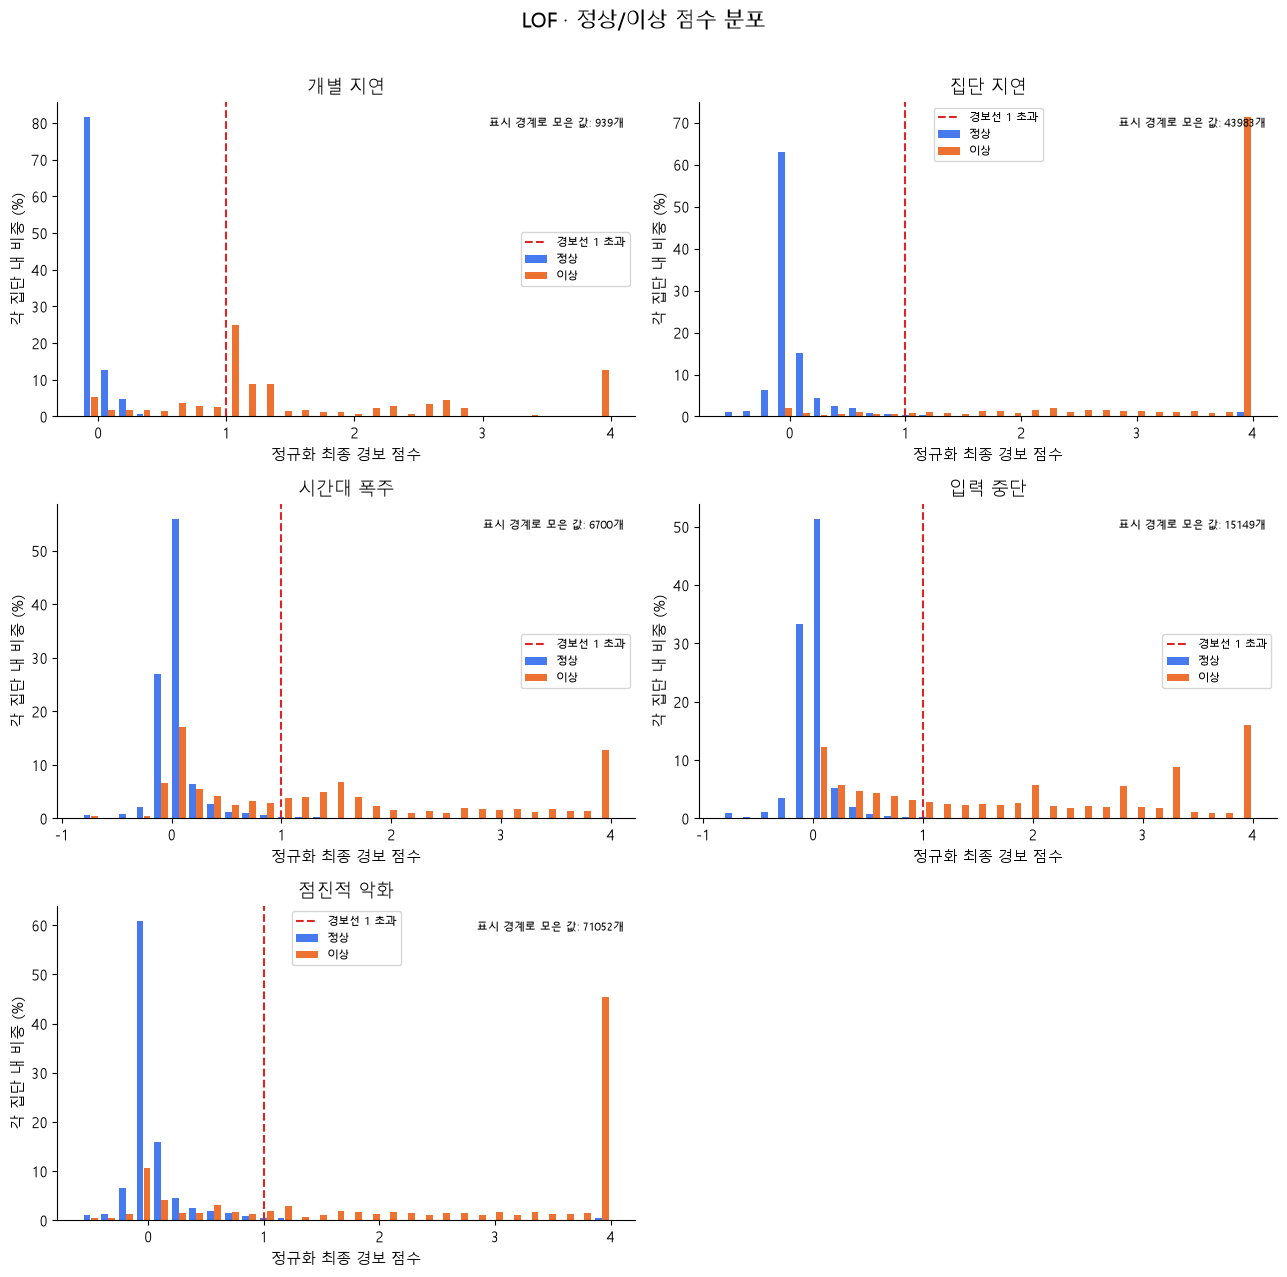

In [10]:
a='lof';ai=2
fig,axes=plt.subplots(3,2,figsize=(13,13));axes=axes.ravel()
for j,t in enumerate(tasks):
    z=np.load(LOG/(t+'_scores.npz'));score=z['scores'][:,ai];y=z['y'];ax=axes[j]
    lo=min(0.,float(np.quantile(score,.005)));hi=max(1.5,min(4.,float(np.quantile(score,.995))));edges=np.linspace(lo,hi,31);width=np.diff(edges);centers=(edges[:-1]+edges[1:])/2
    for shift,mask,color,label in [(-.2,~y,'#2563eb','정상'),(.2,y,'#ea580c','이상')]:
        hist=np.histogram(np.clip(score[mask],lo,hi),bins=edges)[0]/max(mask.sum(),1)*100
        ax.bar(centers+shift*width,hist,width=.39*width,color=color,alpha=.85,label=label)
    ax.axvline(1.,color='#dc2626',ls='--',label='경보선 1 초과')
    ax.set(title=labels[j],xlabel='정규화 최종 경보 점수',ylabel='각 집단 내 비중 (%)')
    ax.text(.98,.95,'표시 경계로 모은 값: '+str(int(((score<lo)|(score>hi)).sum()))+'개',ha='right',va='top',transform=ax.transAxes,fontsize=8)
    ax.legend(fontsize=8)
axes[-1].axis('off');fig.suptitle(names[a]+' · 정상/이상 점수 분포',fontsize=15);fig.tight_layout(rect=[0,0,1,.97]);fig.savefig(LOG/(a+'_score_distribution.png'),dpi=130,bbox_inches='tight');display(fig);plt.close(fig)

## 6. 판정 근거와 실시간 사용

1. 백엔드가 **현재 시점까지의 완료 Process 로그**와 분 단위 유입 개수를 전달한다.
2. 과거 정상 통계와 지금까지의 관측으로 지연·추세·폭주·공백 피처를 만든다. 미래 t+k까지 기다려 과거를 다시 판정하지 않는다.
3. 단일 학습 모델 점수에 정상 소요시간 이웃 및 과거 방향 요청 수 상태 신호를 결합한다. 이 상태 신호는 장애 확률로 보정된 값이 아니다.
4. 관측 신호·과거 지원량·Adapter에 맞는 **개발 단계에서 선택한 경보 기준표**를 적용한다. 이것은 Adapter별 학습 모델과 다르다.
5. 정규화 점수 >1이면 경보. 새 Adapter는 같은 단일 추정기의 고정된 기존 기준으로 처리한다.

‘점진적 악화로 확정’처럼 원인을 단정하는 분류기는 아니다. 여러 근거 중 지연 추세가 높으면 ‘최근 소요시간 증가가 경보 근거’라고 설명한다. 실제 장애 유형과 조치는 운영자가 확인해야 한다.

입력 중단은 **로그가 안 들어온 분에도 실행되는 타이머**가 필요하다. 현재 Monitor는 연속 분 격자와 과거 prefix를 받아 계산하며, 상태 보관·빈 분 생성·지연 도착·서버 배포는 별도 backend/worker 구현이다.

## 7. 검증 범위와 남은 한계

- 원 벤치마크의 행·정답·난도 변경 없음. 원 기간 데이터, ADBench, 기존 v6 모델도 변경하지 않음.
- 모든 5개 시나리오×세 모델, 총 1,927,972개 분 판정 전수 평가 및 sklearn 지표 독립 재계산.
- 학습 추정기에는 정상 참조만 사용. 그러나 정상 후보가 실제 운영에서 완전히 정상이라는 보장은 없음.
- 설정·피처·조건부 경보 기준을 고르는 데 **동일 개발 벤치마크 정답을 여러 번 사용**. 별도 미사용 기간·새로운 실제 장애 평가가 필요.
- 미래 비참조, 짝 정상/이상 스트림 상태 초기화, 미지 Adapter, 저장·로드, raw Process 입력, 런타임 데이터 파일 비참조 검증.
- 일반적인 모델별 역할은 이 데이터에서 관측한 수치로만 표현. 합성 생성기 패턴이나 정상 시간대 분포가 실제 환경과 다르면 순위·성능이 달라질 수 있음.
- 6%는 사용자 허용 상한이며 운영 오탐률 보장이나 통계적 유의성 주장이 아님.

참고: [Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html), [MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html), [novelty LOF](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html). 요청 수 상태의 시간적 누적은 [Kleinberg, 2002](https://www.cs.cornell.edu/info/people/kleinber/bhs.pdf)의 burst-state 관점에서 착안했지만 논문의 원 알고리즘을 재현한 것은 아니다.

In [11]:
display(pd.DataFrame([{'모델':names[a],**{k:v for k,v in s['acceptance']['algorithms'][a].items()if k not in ['tasks']}}for a in alg]))
display(read(LOG/'audit.json'))
display(pd.DataFrame([{'모델':names[r['algorithm']],'파일':r['file'],'크기(MiB)':r['bytes']/1024**2,'경보선':r['threshold']}for r in handoff['models']]).round(3))

,모델,pooled_nonregression,all_task_metrics_met,minimum_task_Recall,all_met
0,Isolation Forest,True,True,0.564746,True
1,MiniBatch K-means,True,True,0.557641,True
2,LOF,True,True,0.554233,True


{'independent_metrics_recomputed': True,
 'raw_serving_smoke_checks': [{'algorithm': 'if',
   'raw_Process_predict': True,
   'prefix_causal': True,
   'unknown_adapter_finite': True,
   'save_load_identical': True,
   'no_runtime_data_reads': True,
   'research_only_not_promoted': True},
  {'algorithm': 'kmeans',
   'raw_Process_predict': True,
   'prefix_causal': True,
   'unknown_adapter_finite': True,
   'save_load_identical': True,
   'no_runtime_data_reads': True,
   'research_only_not_promoted': True},
  {'algorithm': 'lof',
   'raw_Process_predict': True,
   'prefix_causal': True,
   'unknown_adapter_finite': True,
   'save_load_identical': True,
   'no_runtime_data_reads': True,
   'research_only_not_promoted': True}],
 'all_targets_met': True,
 'published': False,
 'external_blind_test': False,
 'published_local_research_handoff': True,
 'all_benchmark_file_hashes_verified': True,
 'ADBench_and_v6_unchanged': True,
 'one_unique_fault_estimator_each_verified': True,
 'model_sh

,모델,파일,크기(MiB),경보선
0,Isolation Forest,if_shared.joblib,1.076,1.0
1,MiniBatch K-means,kmeans_shared.joblib,0.797,1.0
2,LOF,lof_shared.joblib,11.618,1.0


## 8. 전달 파일

`reports/shared_model_v7/release/handoff/{if,kmeans,lof}_shared.joblib`는 정상 참조와 전처리 컨텍스트를 포함하는 Monitor다. `manifest.json`에는 패키지 버전과 해시·입력 계약이 있다. 로컬 `code/` 모듈도 함께 필요하며 joblib 파일만 복사하는 것으로 독립 실행되지는 않는다. 신뢰할 수 있는 모델 파일만 로드해야 한다.

이번 작업은 **로컬 연구 결과 갱신**이다. Git push·Notion 수정·운영 서비스 배포는 수행하지 않았다.